# CS5812 Predictive Data Analysis — Abhishek’s Models

**ML:** Logistic Regression (L1 / L2 / ElasticNet Regularisation)  
**DL:** Autoencoder + Classifier Head  

> 80/20 stratified split · SMOTE on training only · `random_state=42`

In [1]:
"""
CS5812 Predictive Data Analysis — Abhishek's Individual Models
================================================================
ML:  Logistic Regression (L1 / L2 Regularisation)
DL:  Autoencoder + Classifier Head

Same dataset, 80/20 stratified split (random_state=42), SMOTE on training only.
"""

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from pathlib import Path

# Sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, f1_score, accuracy_score,
    average_precision_score
)

# SMOTE
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, Model
from sklearn.manifold import TSNE

def focal_loss(gamma=2.0, alpha=0.25):
    def loss(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
        bce   = -y_true * tf.math.log(y_pred) - (1 - y_true) * tf.math.log(1 - y_pred)
        p_t   = y_true * y_pred + (1 - y_true) * (1 - y_pred)
        return tf.reduce_mean(alpha * tf.pow(1 - p_t, gamma) * bce)
    return loss


I0000 00:00:1793597915.470096    4402 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793597915.521394    4402 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793597920.491548    4402 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# ──────────────────────────────────────────────
# CONFIG
# ──────────────────────────────────────────────
import os

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Relative paths — works on any PC as long as the Excel file is in the same folder as this notebook
DATA_PATH = Path(os.getcwd()) / "telecom_customer_churn_20_columns.xlsx"
OUTDIR    = Path(os.getcwd()) / "outputs"
FIGDIR    = OUTDIR / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)

print("Data file:", DATA_PATH)
print("Output folder:", OUTDIR)

Data file: ./telecom_customer_churn_20_columns.xlsx
Output folder: ./outputs


## Section 1: Data Preparation

In [3]:
print("=" * 70)
print("SECTION 1: DATA PREPARATION")
print("=" * 70)

df_raw = pd.read_excel(DATA_PATH)
print(f"Raw dataset: {df_raw.shape[0]} rows × {df_raw.shape[1]} columns\n")

# --- 1a. Clamp negative Monthly Charge ---
neg_count = (df_raw["Monthly Charge"] < 0).sum()
print(f"Negative Monthly Charge records clamped to 0: {neg_count}")
df = df_raw.copy()
df["Monthly Charge"] = df["Monthly Charge"].clip(lower=0)

# --- 1b. Context-aware imputation ---
df["Offer"]                  = df["Offer"].fillna("No Offer")
df["Internet Type"]          = df["Internet Type"].fillna("No Internet")
df["Online Security"]        = df["Online Security"].fillna("No Internet")
df["Online Backup"]          = df["Online Backup"].fillna("No Internet")
df["Device Protection Plan"] = df["Device Protection Plan"].fillna("No Internet")
df["Premium Tech Support"]   = df["Premium Tech Support"].fillna("No Internet")
df["Multiple Lines"]         = df["Multiple Lines"].fillna("No Phone Service")
assert df.isna().sum().sum() == 0, "Missing values remain!"
print("Missing values after cleaning: 0")

# --- 1c. Feature engineering ---
df["Churn"] = (df["Customer Status"] == "Churned").astype(int)

df["Service_Score"] = (
    (df["Online Security"]        == "Yes").astype(int) +
    (df["Online Backup"]          == "Yes").astype(int) +
    (df["Device Protection Plan"] == "Yes").astype(int) +
    (df["Premium Tech Support"]   == "Yes").astype(int) +
    (df["Multiple Lines"]         == "Yes").astype(int)
)

df["ARPU"]   = df["Monthly Charge"] / (df["Tenure in Months"] + 1)
df["Senior"] = (df["Age"] >= 65).astype(int)

print(f"Engineered features added: Churn, Service_Score, ARPU, Senior")
print(f"Churn rate: {df['Churn'].mean()*100:.1f}%\n")

# --- 1c-extra. Interaction features ---
df["Tenure_x_MonthToMonth"] = df["Tenure in Months"] * (df["Contract"] == "Month-to-Month").astype(int)
df["Charge_x_Senior"]       = df["Monthly Charge"] * df["Senior"]

# --- 1d. Model encoding ---
binary_cols = [
    "Gender", "Married", "Phone Service", "Internet Service",
    "Multiple Lines", "Online Security", "Online Backup",
    "Device Protection Plan", "Premium Tech Support"
]

df_model = df.drop(columns=["Customer ID", "Customer Status"])

# Binary encode Yes/No columns → 0/1
for col in binary_cols:
    cats = sorted(df_model[col].unique())
    df_model[col] = pd.Categorical(df_model[col], categories=cats).codes

# One-hot encode multi-class categoricals
ohe_cols = ["Offer", "Internet Type", "Contract", "Payment Method"]
df_model = pd.get_dummies(df_model, columns=ohe_cols, drop_first=False, dtype=int)

# Clean column names (remove spaces for consistency)
df_model.columns = df_model.columns.str.replace(" ", "_")

# Drop Total_Charges highly collinear with Monthly_Charge * Tenure_in_Months
df_model = df_model.drop(columns=["Total_Charges"])

print(f"Model-ready dataset: {df_model.shape[0]} rows × {df_model.shape[1]} columns")
print(f"Feature columns: {df_model.shape[1] - 1}")

# --- 1e. Train-test split (80/20, stratified, random_state=42) ---
y = df_model["Churn"]
X = df_model.drop(columns=["Churn"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print(f"\nTrain: {X_train.shape[0]} rows  |  Test: {X_test.shape[0]} rows")
print(f"Train churn rate: {y_train.mean()*100:.1f}%")
print(f"Test  churn rate: {y_test.mean()*100:.1f}%")

n_features = X_train.shape[1]
print(f"Number of input features: {n_features}")


SECTION 1: DATA PREPARATION


Raw dataset: 7043 rows × 20 columns

Negative Monthly Charge records clamped to 0: 120
Missing values after cleaning: 0
Engineered features added: Churn, Service_Score, ARPU, Senior
Churn rate: 26.5%

Model-ready dataset: 7043 rows × 35 columns
Feature columns: 34

Train: 5634 rows  |  Test: 1409 rows
Train churn rate: 26.5%
Test  churn rate: 26.5%
Number of input features: 34


## Section 2: Logistic Regression (L1 / L2 / ElasticNet)

In [4]:
# --- 2a. Scale features (LR is scale-sensitive) ---
scaler_lr = StandardScaler()
X_train_scaled = scaler_lr.fit_transform(X_train)
X_test_scaled  = scaler_lr.transform(X_test)


In [5]:
# --- 2b. Apply SMOTE to training data only ---
smote = SMOTE(random_state=SEED)
X_train_sm, y_train_sm = smote.fit_resample(X_train_scaled, y_train)
print(f"After SMOTE — Train: {len(y_train_sm)} rows  "
      f"(Churn=1: {y_train_sm.sum()}, Churn=0: {(y_train_sm==0).sum()})")


After SMOTE — Train: 8278 rows  (Churn=1: 4139, Churn=0: 4139)


In [6]:
# --- 2c. GridSearchCV — L1, L2 and ElasticNet with saga solver ---
param_grid = [
    {"penalty": ["l1", "l2"],      "C": [0.01, 0.1, 0.5, 1, 5, 10]},
    {"penalty": ["elasticnet"],    "C": [0.01, 0.1, 0.5, 1, 5, 10], "l1_ratio": [0.3, 0.5, 0.7]}
]

lr_base = LogisticRegression(
    solver="saga",
    max_iter=5000,
    random_state=SEED
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

grid_search = GridSearchCV(
    lr_base, param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=0,
    refit=True
)

grid_search.fit(X_train_sm, y_train_sm)

best_lr = grid_search.best_estimator_
print(f"\nBest hyperparameters: {grid_search.best_params_}")
print(f"Best CV AUC-ROC:     {grid_search.best_score_:.4f}")



Best hyperparameters: {'C': 10, 'l1_ratio': 0.5, 'penalty': 'elasticnet'}
Best CV AUC-ROC:     0.8907


In [7]:
# --- 2d. Evaluate on test set ---
y_prob_lr  = best_lr.predict_proba(X_test_scaled)[:, 1]
y_pred_lr  = best_lr.predict(X_test_scaled)

auc_lr     = roc_auc_score(y_test, y_prob_lr)
f1_lr      = f1_score(y_test, y_pred_lr)
acc_lr     = accuracy_score(y_test, y_pred_lr)
ap_lr      = average_precision_score(y_test, y_prob_lr)

print(f"\n--- Logistic Regression Test Results (default threshold=0.50) ---")
print(f"Accuracy:           {acc_lr:.4f}")
print(f"F1 Score:           {f1_lr:.4f}")
print(f"AUC-ROC:            {auc_lr:.4f}")
print(f"Average Precision:  {ap_lr:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_lr, target_names=["Stayed/Joined", "Churned"]))

# --- 2d-extra. Threshold tuning for LR ---
print("\n--- Threshold Tuning (LR) ---")
thresholds_lr = np.arange(0.20, 0.65, 0.01)
f1_scores_lr  = [f1_score(y_test, (y_prob_lr >= t).astype(int)) for t in thresholds_lr]
best_thresh_lr = thresholds_lr[np.argmax(f1_scores_lr)]

y_pred_lr_tuned = (y_prob_lr >= best_thresh_lr).astype(int)
f1_lr_tuned  = f1_score(y_test, y_pred_lr_tuned)
acc_lr_tuned = accuracy_score(y_test, y_pred_lr_tuned)

print(f"Optimal threshold: {best_thresh_lr:.2f}")
print(f"F1 at optimal threshold: {f1_lr_tuned:.4f}")
print(f"Accuracy at optimal threshold: {acc_lr_tuned:.4f}")
print(f"\nClassification Report (tuned threshold={best_thresh_lr:.2f}):")
print(classification_report(y_test, y_pred_lr_tuned, target_names=["Stayed/Joined", "Churned"]))



--- Logistic Regression Test Results (default threshold=0.50) ---
Accuracy:           0.7686
F1 Score:           0.6517
AUC-ROC:            0.8734
Average Precision:  0.7270

Classification Report:
               precision    recall  f1-score   support

Stayed/Joined       0.92      0.75      0.83      1035
      Churned       0.54      0.82      0.65       374

     accuracy                           0.77      1409
    macro avg       0.73      0.78      0.74      1409
 weighted avg       0.82      0.77      0.78      1409


--- Threshold Tuning (LR) ---
Optimal threshold: 0.62
F1 at optimal threshold: 0.6675
Accuracy at optimal threshold: 0.8091

Classification Report (tuned threshold=0.62):
               precision    recall  f1-score   support

Stayed/Joined       0.89      0.84      0.87      1035
      Churned       0.62      0.72      0.67       374

     accuracy                           0.81      1409
    macro avg       0.76      0.78      0.77      1409
 weighted avg      

In [8]:
# --- 2e. Coefficient analysis (interpretability) ---
coef_df = pd.DataFrame({
    "Feature":     X.columns,
    "Coefficient": best_lr.coef_[0],
    "Odds_Ratio":  np.exp(best_lr.coef_[0])
}).sort_values("Coefficient", ascending=False)

print("\n--- Top 10 Positive Churn Drivers (log-odds) ---")
print(coef_df.head(10).to_string(index=False))
print("\n--- Top 10 Negative Churn Drivers (protective) ---")
print(coef_df.tail(10).to_string(index=False))

coef_df.to_csv(OUTDIR / "lr_coefficients.csv", index=False)



--- Top 10 Positive Churn Drivers (log-odds) ---
                    Feature  Coefficient  Odds_Ratio
    Contract_Month-to-Month     1.245528    3.474769
             Monthly_Charge     1.030922    2.803651
                     Senior     0.548698    1.730998
                       ARPU     0.206435    1.229288
           Tenure_in_Months     0.200749    1.222318
             Multiple_Lines     0.172972    1.188833
  Internet_Type_No_Internet     0.139324    1.149497
Payment_Method_Mailed_Check     0.118433    1.125731
                    Married     0.086486    1.090336
        Internet_Type_Cable     0.084536    1.088212

--- Top 10 Negative Churn Drivers (protective) ---
                   Feature  Coefficient  Odds_Ratio
          Internet_Service    -0.139324    0.869946
         Contract_One_Year    -0.143291    0.866502
      Premium_Tech_Support    -0.172836    0.841275
           Online_Security    -0.188255    0.828404
Payment_Method_Credit_Card    -0.213293    0.807919
   

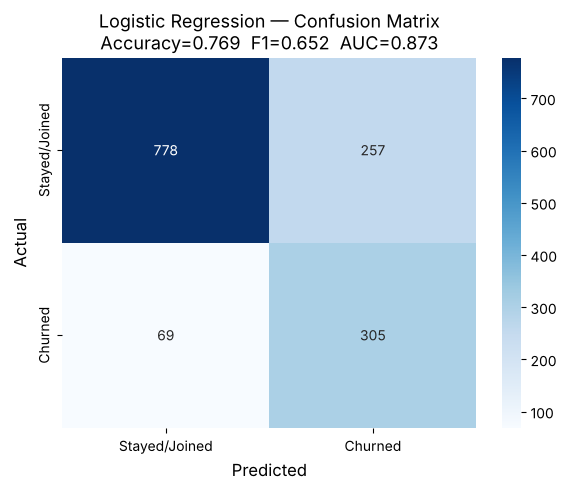


Saved: fig_lr_confusion_matrix.png


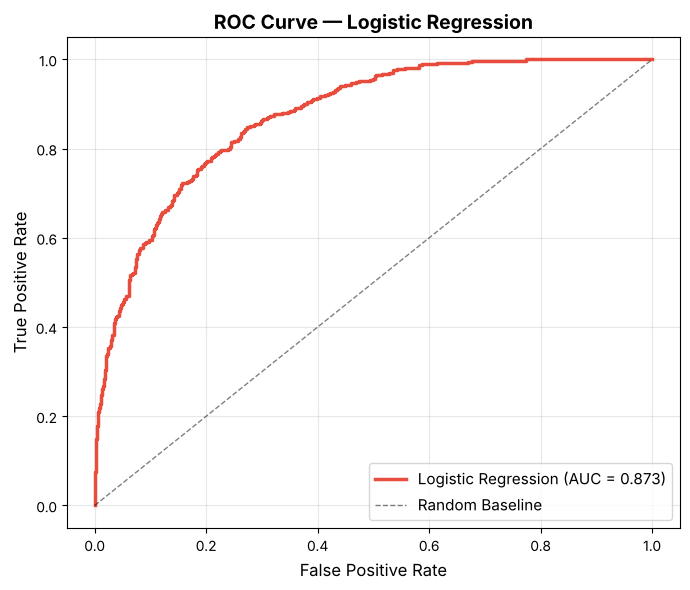

Saved: fig_lr_roc_curve.png


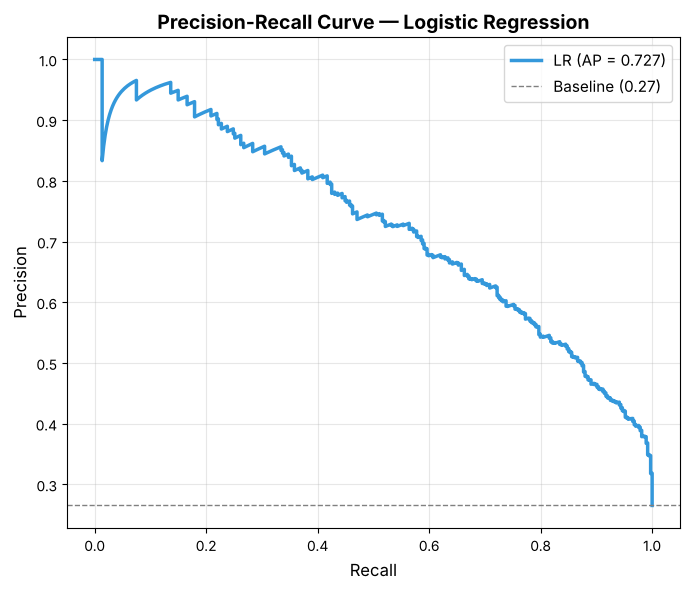

Saved: fig_lr_precision_recall.png


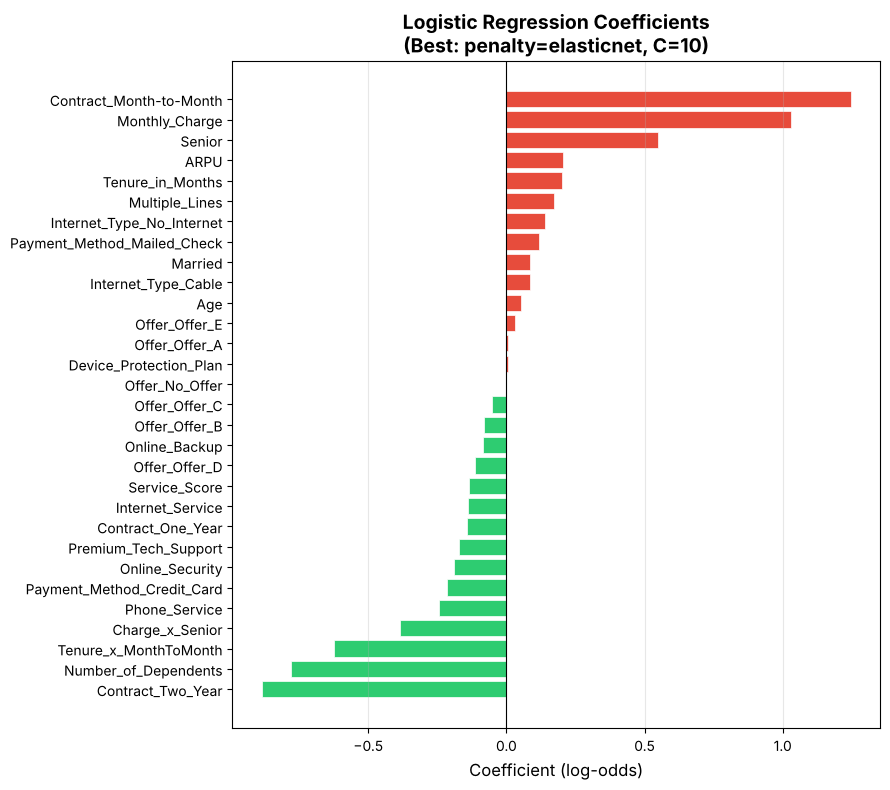

Saved: fig_lr_coefficients.png


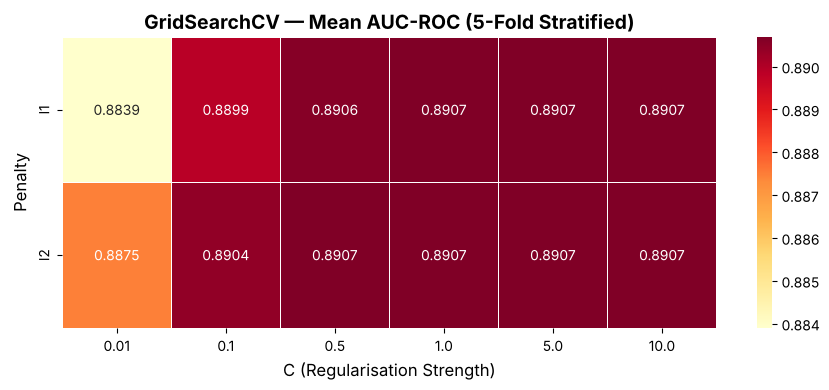

Saved: fig_lr_gridsearch_heatmap.png


In [9]:
# --- 2f. Figures ---

# Fig LR-1: Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stayed/Joined", "Churned"],
            yticklabels=["Stayed/Joined", "Churned"], ax=ax)
ax.set_xlabel("Predicted", fontsize=12)
ax.set_ylabel("Actual", fontsize=12)
ax.set_title(f"Logistic Regression — Confusion Matrix\nAccuracy={acc_lr:.3f}  F1={f1_lr:.3f}  AUC={auc_lr:.3f}", fontsize=13)
plt.tight_layout()
plt.savefig(FIGDIR / "fig_lr_confusion_matrix.png", dpi=150)
plt.show()
print("\nSaved: fig_lr_confusion_matrix.png")

# Fig LR-2: ROC Curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr_lr, tpr_lr, color="#E74C3C", lw=2.5, label=f"Logistic Regression (AUC = {auc_lr:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5, label="Random Baseline")
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)
ax.set_title("ROC Curve — Logistic Regression", fontsize=14, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGDIR / "fig_lr_roc_curve.png", dpi=150)
plt.show()
print("Saved: fig_lr_roc_curve.png")

# Fig LR-3: Precision-Recall Curve
prec_lr, rec_lr, _ = precision_recall_curve(y_test, y_prob_lr)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(rec_lr, prec_lr, color="#3498DB", lw=2.5, label=f"LR (AP = {ap_lr:.3f})")
ax.axhline(y=y_test.mean(), color="grey", linestyle="--", lw=1, label=f"Baseline ({y_test.mean():.2f})")
ax.set_xlabel("Recall", fontsize=12)
ax.set_ylabel("Precision", fontsize=12)
ax.set_title("Precision-Recall Curve — Logistic Regression", fontsize=14, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGDIR / "fig_lr_precision_recall.png", dpi=150)
plt.show()
print("Saved: fig_lr_precision_recall.png")

# Fig LR-4: Top 15 Coefficient Bar Plot
top_n = 15
coef_top = pd.concat([coef_df.head(top_n), coef_df.tail(top_n)]).drop_duplicates()
coef_top = coef_top.sort_values("Coefficient")

fig, ax = plt.subplots(figsize=(9, 8))
colors = ["#E74C3C" if c > 0 else "#2ECC71" for c in coef_top["Coefficient"]]
ax.barh(coef_top["Feature"], coef_top["Coefficient"], color=colors, edgecolor="white", linewidth=0.5)
ax.axvline(x=0, color="black", linewidth=0.8)
ax.set_xlabel("Coefficient (log-odds)", fontsize=12)
ax.set_title(f"Logistic Regression Coefficients\n(Best: penalty={grid_search.best_params_['penalty']}, C={grid_search.best_params_['C']})",
             fontsize=14, fontweight="bold")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGDIR / "fig_lr_coefficients.png", dpi=150)
plt.show()
print("Saved: fig_lr_coefficients.png")

# Fig LR-5: GridSearch Heatmap (C vs penalty — 11/12 only for readability)
results_df = pd.DataFrame(grid_search.cv_results_)
pivot = results_df[results_df["param_penalty"].isin(["l1", "l2"])].pivot_table(
    values="mean_test_score",
    index="param_penalty",
    columns="param_C"
)
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(pivot, annot=True, fmt=".4f", cmap="YlOrRd", ax=ax, linewidths=0.5)
ax.set_xlabel("C (Regularisation Strength)", fontsize=12)
ax.set_ylabel("Penalty", fontsize=12)
ax.set_title("GridSearchCV — Mean AUC-ROC (5-Fold Stratified)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGDIR / "fig_lr_gridsearch_heatmap.png", dpi=150)
plt.show()
print("Saved: fig_lr_gridsearch_heatmap.png")


## Section 3: Autoencoder + Classifier Head

In [10]:
# --- 3a. Scale features (reuse scaler from LR for consistency) ---
scaler_ae = StandardScaler()
X_train_ae = scaler_ae.fit_transform(X_train)
X_test_ae  = scaler_ae.transform(X_test)

# Class weights instead of SMOTE for AE classifier (handles imbalance without oversampling)
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight_dict = {0: cw[0], 1: cw[1]}
print(f"Class weights — 0 (Stayed): {cw[0]:.3f}  |  1 (Churned): {cw[1]:.3f}")

print(f"Input features: {n_features}")
print(f"Architecture: {n_features} -> 64 -> 32 -> 16 (bottleneck) -> 32 -> 64 -> {n_features}")


Class weights — 0 (Stayed): 0.681  |  1 (Churned): 1.884
Input features: 34
Architecture: 34 -> 64 -> 32 -> 16 (bottleneck) -> 32 -> 64 -> 34


In [11]:
# --- 3b. Build Autoencoder (unsupervised pre-training) ---
BOTTLENECK_DIM = 16

# Encoder
encoder_input = keras.Input(shape=(n_features,), name="encoder_input")
e = layers.Dense(64, activation="relu", name="enc_dense1")(encoder_input)
e = layers.BatchNormalization(name="enc_bn1")(e)
e = layers.Dropout(0.2, name="enc_drop1")(e)
e = layers.Dense(32, activation="relu", name="enc_dense2")(e)
e = layers.BatchNormalization(name="enc_bn2")(e)
e = layers.Dropout(0.2, name="enc_drop2")(e)
bottleneck = layers.Dense(BOTTLENECK_DIM, activation="relu", name="bottleneck")(e)

encoder = Model(encoder_input, bottleneck, name="encoder")

# Decoder
decoder_input = keras.Input(shape=(BOTTLENECK_DIM,), name="decoder_input")
d = layers.Dense(32, activation="relu", name="dec_dense1")(decoder_input)
d = layers.BatchNormalization(name="dec_bn1")(d)
d = layers.Dense(64, activation="relu", name="dec_dense2")(d)
d = layers.BatchNormalization(name="dec_bn2")(d)
decoder_output = layers.Dense(n_features, activation="linear", name="dec_output")(d)

decoder = Model(decoder_input, decoder_output, name="decoder")

# Full Autoencoder
ae_input = keras.Input(shape=(n_features,), name="ae_input")
encoded = encoder(ae_input)
decoded = decoder(encoded)
autoencoder = Model(ae_input, decoded, name="autoencoder")

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

print("\n--- Autoencoder Architecture ---")
autoencoder.summary()



--- Autoencoder Architecture ---


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ae_input (InputLayer)           │ (None, 34)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 16)             │         5,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 34)             │         5,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,482 (40.95 KB)

 Trainable params: 10,098 (39.45 KB)

 Non-trainable params: 384 (1.50 KB)


--- Training Autoencoder (unsupervised) ---


Epoch 1/100


 1/75 ━━━━━━━━━━━━━━━━━━━━ 3:38 3s/step - loss: 2.2881

19/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.8465 

41/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.5719

61/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.4085

... (597 outputs left out)

65/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1447

75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1442 - val_loss: 0.0408 - learning_rate: 0.0010


Restoring model weights from the end of the best epoch: 100.



Reconstruction MSE — Train: 0.0405  |  Test: 0.0403


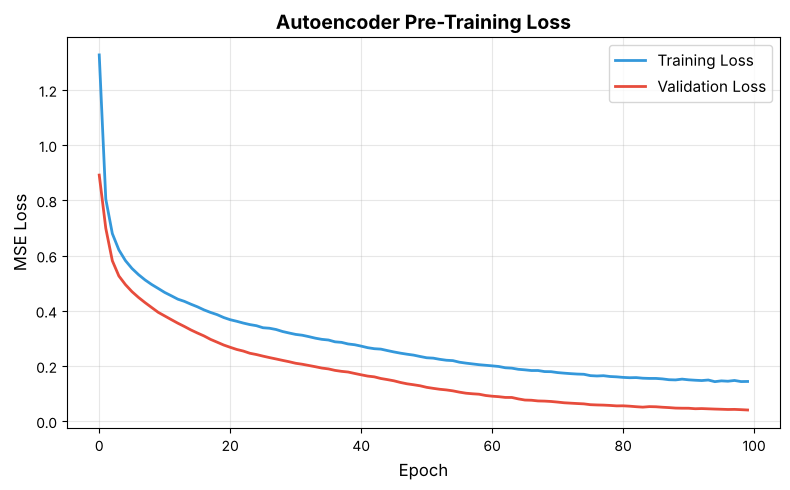

Saved: fig_ae_pretraining_loss.png


In [12]:
# --- 3c. Train Autoencoder (unsupervised uses ALL training data, no labels) ---
ae_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_loss", patience=10,
        restore_best_weights=True, verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=5, verbose=1
    )
]

print("\n--- Training Autoencoder (unsupervised) ---")
ae_history = autoencoder.fit(
    X_train_ae, X_train_ae,
    epochs=100,
    batch_size=64,
    validation_split=0.15,
    callbacks=ae_callbacks,
    verbose=1
)

# Reconstruction error
recon_train = autoencoder.predict(X_train_ae, verbose=0)
recon_test  = autoencoder.predict(X_test_ae, verbose=0)
mse_train = np.mean((X_train_ae - recon_train) ** 2)
mse_test  = np.mean((X_test_ae - recon_test) ** 2)
print(f"\nReconstruction MSE — Train: {mse_train:.4f}  |  Test: {mse_test:.4f}")

# Fig AE-1: Autoencoder training loss
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ae_history.history["loss"], label="Training Loss", color="#3498DB", lw=2)
ax.plot(ae_history.history["val_loss"], label="Validation Loss", color="#E74C3C", lw=2)
ax.set_xlabel("Epoch", fontsize=12)
ax.set_ylabel("MSE Loss", fontsize=12)
ax.set_title("Autoencoder Pre-Training Loss", fontsize=14, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGDIR / "fig_ae_pretraining_loss.png", dpi=150)
plt.show()
print("Saved: fig_ae_pretraining_loss.png")



--- Computing t-SNE on bottleneck representations ---


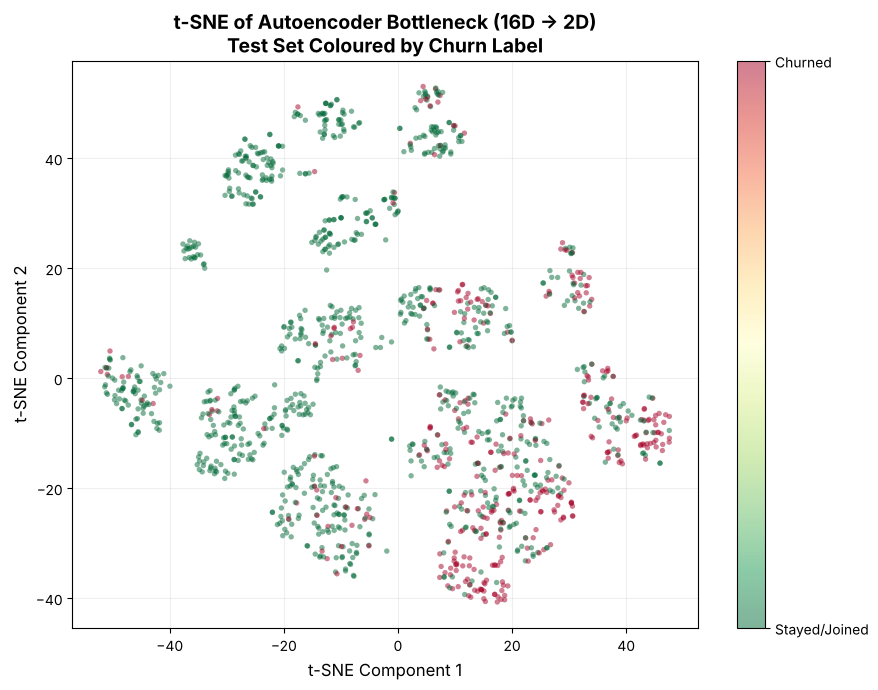

Saved: fig_ae_tsne_bottleneck.png


In [13]:
# --- 3d. t-SNE Visualisation of Bottleneck ---
print("\n--- Computing t-SNE on bottleneck representations ---")
bottleneck_train = encoder.predict(X_train_ae, verbose=0)
bottleneck_test  = encoder.predict(X_test_ae, verbose=0)

# Use test set for cleaner visualisation
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30, max_iter=1000)
tsne_emb = tsne.fit_transform(bottleneck_test)

fig, ax = plt.subplots(figsize=(9, 7))
scatter = ax.scatter(
    tsne_emb[:, 0], tsne_emb[:, 1],
    c=y_test.values, cmap="RdYlGn_r", alpha=0.5, s=15, edgecolors="none"
)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(["Stayed/Joined", "Churned"])
ax.set_xlabel("t-SNE Component 1", fontsize=12)
ax.set_ylabel("t-SNE Component 2", fontsize=12)
ax.set_title("t-SNE of Autoencoder Bottleneck (16D -> 2D)\nTest Set Coloured by Churn Label",
             fontsize=14, fontweight="bold")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGDIR / "fig_ae_tsne_bottleneck.png", dpi=150)
plt.show()
print("Saved: fig_ae_tsne_bottleneck.png")


In [14]:
# --- 3e. Freeze Encoder + Add Classifier Head ---
print("\n--- Building Classifier Head (freeze encoder) ---")

# Freeze encoder weights
for layer in encoder.layers:
    layer.trainable = False

clf_input = keras.Input(shape=(n_features,), name="clf_input")
z = encoder(clf_input)
z = layers.Dense(32, activation="relu", name="clf_dense1")(z)
z = layers.BatchNormalization(name="clf_bn1")(z)
z = layers.Dropout(0.3, name="clf_drop1")(z)
z = layers.Dense(16, activation="relu", name="clf_dense2")(z)
z = layers.BatchNormalization(name="clf_bn2")(z)
z = layers.Dropout(0.2, name="clf_drop2")(z)
clf_output = layers.Dense(1, activation="sigmoid", name="clf_output")(z)

classifier = Model(clf_input, clf_output, name="ae_classifier")

classifier.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss=focal_loss(gamma=2.0, alpha=0.25),
    metrics=["accuracy"]
)

print("\n--- Classifier Head Architecture ---")
classifier.summary()



--- Building Classifier Head (freeze encoder) ---

--- Classifier Head Architecture ---


Model: "ae_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ clf_input (InputLayer)          │ (None, 34)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 16)             │         5,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_dense1 (Dense)              │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_bn1 (BatchNormalization)    │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_drop1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_dense2 (Dense)              │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_bn2 (BatchNormalization)    │ (None, 16)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_drop2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_output (Dense)              │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,513 (25.44 KB)

 Trainable params: 1,185 (4.63 KB)

 Non-trainable params: 5,328 (20.81 KB)

In [15]:
# --- 3f. Train classifier head on SMOTE-balanced data ---
clf_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_loss", patience=10,
        restore_best_weights=True, verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=5, verbose=1
    )
]

print("\n--- Training Classifier Head (supervised, encoder frozen) ---")
clf_history_frozen = classifier.fit(
    X_train_ae, y_train,
    epochs=80,
    batch_size=64,
    validation_split=0.15,
    class_weight=class_weight_dict,
    callbacks=clf_callbacks,
    verbose=1
)



--- Training Classifier Head (supervised, encoder frozen) ---
Epoch 1/80


 1/75 ━━━━━━━━━━━━━━━━━━━━ 1:54 2s/step - accuracy: 0.5469 - loss: 0.1048

22/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5469 - loss: 0.1044 

46/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5588 - loss: 0.0969

69/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5790 - loss: 0.0896

75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5812 - loss: 0.0886 - val_accuracy: 0.6194 - val_loss: 0.0419 - learning_rate: 5.0000e-04


... (241 outputs left out)

70/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7886 - loss: 0.0293

75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7884 - loss: 0.0291 - val_accuracy: 0.8191 - val_loss: 0.0250 - learning_rate: 3.1250e-05


Epoch 45: early stopping


Restoring model weights from the end of the best epoch: 35.


In [16]:
# --- 3g. Fine-tune: unfreeze encoder and train end-to-end with low lr ---
print("\n--- Fine-Tuning: Unfreezing encoder (low learning rate) ---")
for layer in encoder.layers:
    layer.trainable = True

classifier.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00005),
    loss=focal_loss(gamma=2.0, alpha=0.25),
    metrics=["accuracy"]
)

ft_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_loss", patience=8,
        restore_best_weights=True, verbose=1
    )
]

clf_history_ft = classifier.fit(
    X_train_ae, y_train,
    epochs=40,
    batch_size=64,
    validation_split=0.15,
    class_weight=class_weight_dict,
    callbacks=ft_callbacks,
    verbose=1
)



--- Fine-Tuning: Unfreezing encoder (low learning rate) ---


Epoch 1/40


 1/75 ━━━━━━━━━━━━━━━━━━━━ 2:34 2s/step - accuracy: 0.7969 - loss: 0.0301

21/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7798 - loss: 0.0295 

43/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7838 - loss: 0.0297

65/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7827 - loss: 0.0296

... (233 outputs left out)

44/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8008 - loss: 0.0278

66/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8033 - loss: 0.0275

75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8035 - loss: 0.0273 - val_accuracy: 0.8298 - val_loss: 0.0243


Restoring model weights from the end of the best epoch: 40.


In [17]:
# --- 3h. Evaluate on test set ---
y_prob_ae = classifier.predict(X_test_ae, verbose=0).flatten()
y_pred_ae = (y_prob_ae >= 0.5).astype(int)

auc_ae = roc_auc_score(y_test, y_prob_ae)
f1_ae  = f1_score(y_test, y_pred_ae)
acc_ae = accuracy_score(y_test, y_pred_ae)
ap_ae  = average_precision_score(y_test, y_prob_ae)

print(f"\n--- Autoencoder + Classifier Head — Test Results ---")
print(f"Accuracy:           {acc_ae:.4f}")
print(f"F1 Score:           {f1_ae:.4f}")
print(f"AUC-ROC:            {auc_ae:.4f}")
print(f"Average Precision:  {ap_ae:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_ae, target_names=["Stayed/Joined", "Churned"]))

# --- 3i. Threshold tuning ---
print("\n--- Threshold Tuning ---")
thresholds = np.arange(0.20, 0.65, 0.01)
f1_scores = [f1_score(y_test, (y_prob_ae >= t).astype(int)) for t in thresholds]
best_thresh = thresholds[np.argmax(f1_scores)]
best_f1_thresh = max(f1_scores)

y_pred_ae_tuned = (y_prob_ae >= best_thresh).astype(int)
auc_ae_tuned = roc_auc_score(y_test, y_prob_ae)  # AUC doesn't change with threshold
f1_ae_tuned  = f1_score(y_test, y_pred_ae_tuned)
acc_ae_tuned = accuracy_score(y_test, y_pred_ae_tuned)

print(f"Optimal threshold: {best_thresh:.2f}")
print(f"F1 at optimal threshold: {best_f1_thresh:.4f}")
print(f"Accuracy at optimal threshold: {acc_ae_tuned:.4f}")
print(f"\nClassification Report (tuned threshold={best_thresh:.2f}):")
print(classification_report(y_test, y_pred_ae_tuned, target_names=["Stayed/Joined", "Churned"]))



--- Autoencoder + Classifier Head — Test Results ---
Accuracy:           0.8197
F1 Score:           0.6492
AUC-ROC:            0.8692
Average Precision:  0.7228

Classification Report:
               precision    recall  f1-score   support

Stayed/Joined       0.87      0.89      0.88      1035
      Churned       0.67      0.63      0.65       374

     accuracy                           0.82      1409
    macro avg       0.77      0.76      0.76      1409
 weighted avg       0.82      0.82      0.82      1409


--- Threshold Tuning ---
Optimal threshold: 0.45
F1 at optimal threshold: 0.6698
Accuracy at optimal threshold: 0.8027

Classification Report (tuned threshold=0.45):
               precision    recall  f1-score   support

Stayed/Joined       0.90      0.82      0.86      1035
      Churned       0.60      0.75      0.67       374

     accuracy                           0.80      1409
    macro avg       0.75      0.79      0.76      1409
 weighted avg       0.82      0.80   

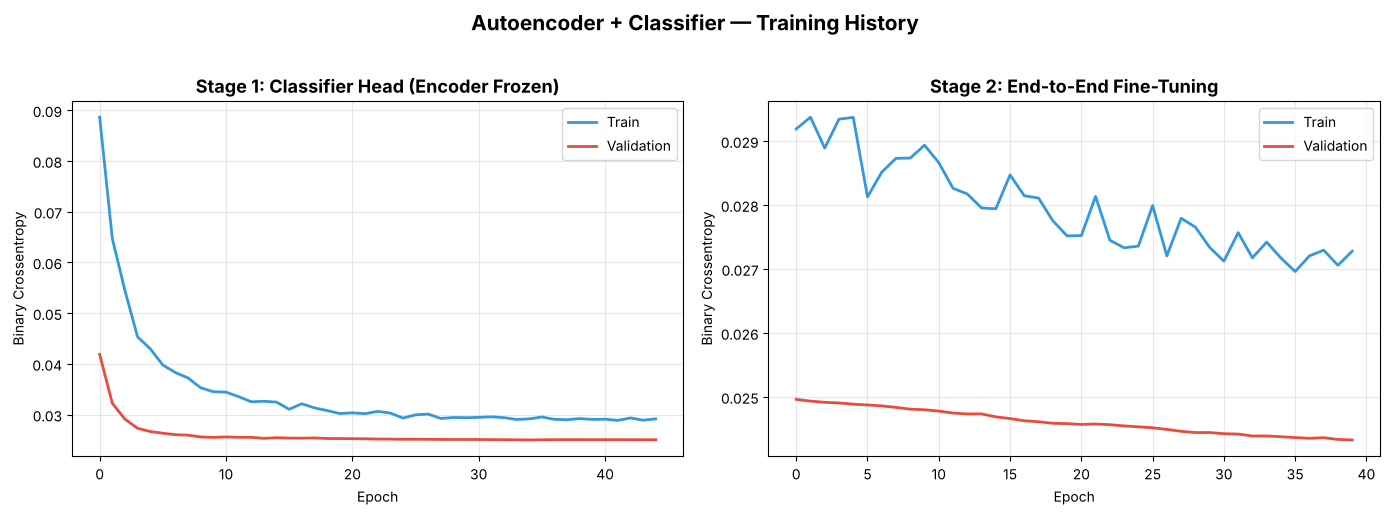


Saved: fig_ae_classifier_training.png


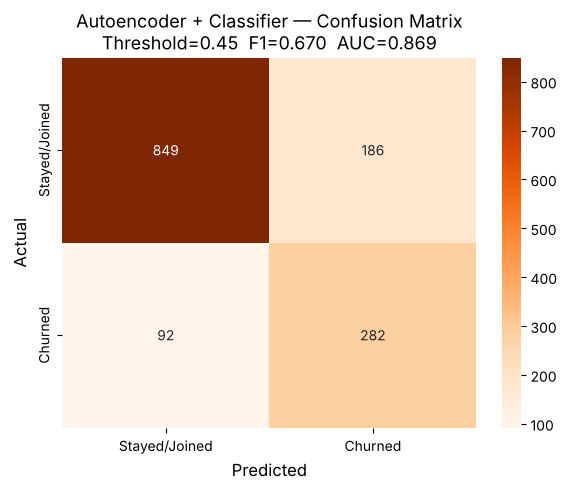

Saved: fig_ae_confusion_matrix.png


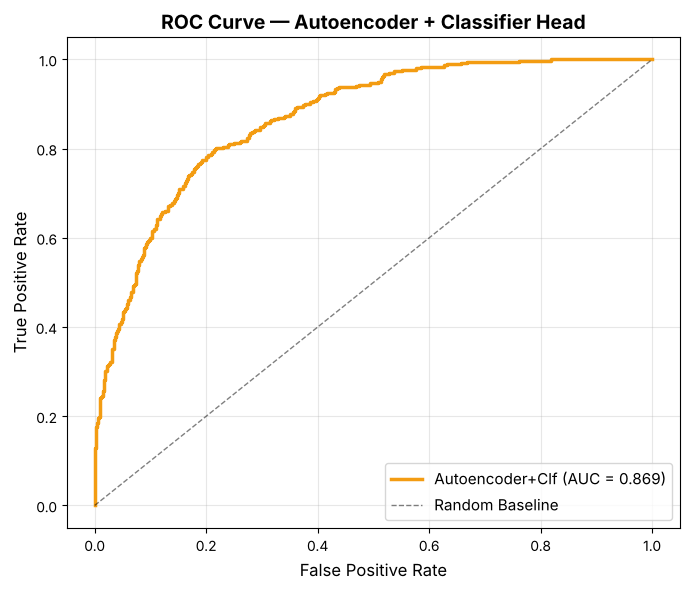

Saved: fig_ae_roc_curve.png


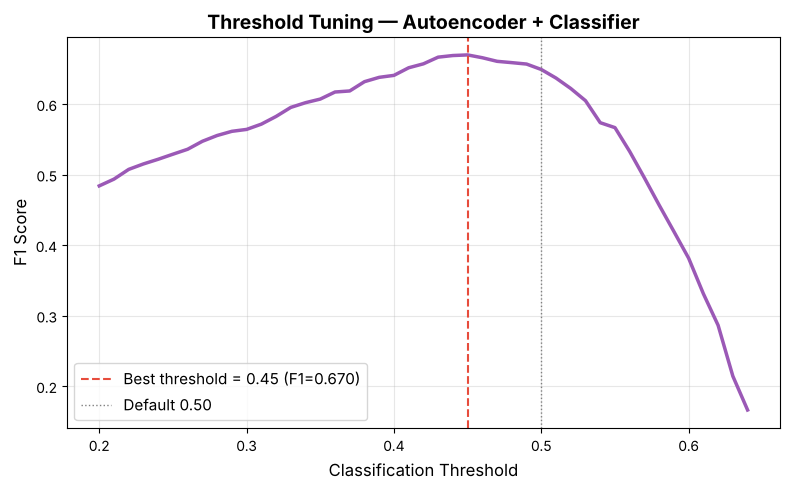

Saved: fig_ae_threshold_tuning.png


In [18]:
# --- 3j. Figures ---

# Fig AE-2: Classifier training loss (frozen + fine-tune)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(clf_history_frozen.history["loss"], label="Train", color="#3498DB", lw=2)
axes[0].plot(clf_history_frozen.history["val_loss"], label="Validation", color="#E74C3C", lw=2)
axes[0].set_title("Stage 1: Classifier Head (Encoder Frozen)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Crossentropy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(clf_history_ft.history["loss"], label="Train", color="#3498DB", lw=2)
axes[1].plot(clf_history_ft.history["val_loss"], label="Validation", color="#E74C3C", lw=2)
axes[1].set_title("Stage 2: End-to-End Fine-Tuning", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary Crossentropy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle("Autoencoder + Classifier — Training History", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIGDIR / "fig_ae_classifier_training.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nSaved: fig_ae_classifier_training.png")

# Fig AE-3: Confusion Matrix (tuned threshold)
fig, ax = plt.subplots(figsize=(6, 5))
cm_ae = confusion_matrix(y_test, y_pred_ae_tuned)
sns.heatmap(cm_ae, annot=True, fmt="d", cmap="Oranges",
            xticklabels=["Stayed/Joined", "Churned"],
            yticklabels=["Stayed/Joined", "Churned"], ax=ax)
ax.set_xlabel("Predicted", fontsize=12)
ax.set_ylabel("Actual", fontsize=12)
ax.set_title(f"Autoencoder + Classifier — Confusion Matrix\nThreshold={best_thresh:.2f}  F1={f1_ae_tuned:.3f}  AUC={auc_ae:.3f}",
             fontsize=13)
plt.tight_layout()
plt.savefig(FIGDIR / "fig_ae_confusion_matrix.png", dpi=150)
plt.show()
print("Saved: fig_ae_confusion_matrix.png")

# Fig AE-4: ROC Curve
fpr_ae, tpr_ae, _ = roc_curve(y_test, y_prob_ae)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr_ae, tpr_ae, color="#F39C12", lw=2.5, label=f"Autoencoder+Clf (AUC = {auc_ae:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5, label="Random Baseline")
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)
ax.set_title("ROC Curve — Autoencoder + Classifier Head", fontsize=14, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGDIR / "fig_ae_roc_curve.png", dpi=150)
plt.show()
print("Saved: fig_ae_roc_curve.png")

# Fig AE-5: Threshold vs F1 Score
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thresholds, f1_scores, color="#9B59B6", lw=2.5)
ax.axvline(x=best_thresh, color="#E74C3C", linestyle="--", lw=1.5,
           label=f"Best threshold = {best_thresh:.2f} (F1={best_f1_thresh:.3f})")
ax.axvline(x=0.50, color="grey", linestyle=":", lw=1, label="Default 0.50")
ax.set_xlabel("Classification Threshold", fontsize=12)
ax.set_ylabel("F1 Score", fontsize=12)
ax.set_title("Threshold Tuning — Autoencoder + Classifier", fontsize=14, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGDIR / "fig_ae_threshold_tuning.png", dpi=150)
plt.show()
print("Saved: fig_ae_threshold_tuning.png")


## Section 4: Comparative Summary


--- Ensemble (Calibrated + Optimised weighted LR + AE probabilities) ---


AE prob range before calibration: [0.070, 0.701]
AE prob range after  calibration: [0.000, 1.000]
Best LR weight: 0.80  |  AE weight: 0.20


Optimal threshold: 0.61
Accuracy:  0.8204
F1 Score:  0.6693
AUC-ROC:   0.8743

Classification Report (Ensemble, threshold=0.61):
               precision    recall  f1-score   support

Stayed/Joined       0.88      0.87      0.88      1035
      Churned       0.65      0.68      0.67       374

     accuracy                           0.82      1409
    macro avg       0.77      0.78      0.77      1409
 weighted avg       0.82      0.82      0.82      1409

                           Model  Accuracy  F1_Score  AUC_ROC  Avg_Precision
     Logistic Regression (tuned)  0.809084  0.667491 0.873448       0.726993
Autoencoder + Classifier (tuned)  0.802697  0.669834 0.869222       0.722760
       Ensemble (LR + AE, tuned)  0.820440  0.669281 0.874313       0.728310


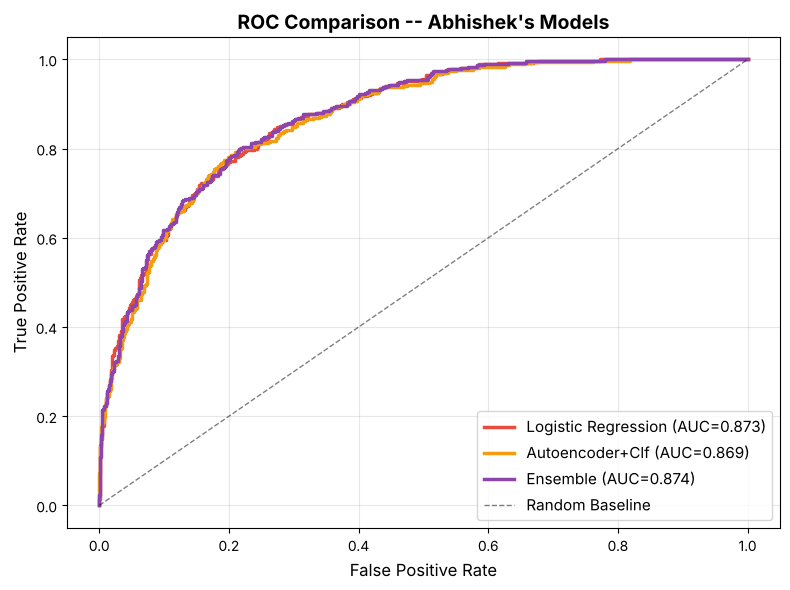


Saved: fig_comparison_roc.png

ALL DONE — outputs saved to: ./outputs
Figures saved to: ./outputs/figures


In [19]:
# --- Ensemble: calibrate AE probs then optimised weighted average ---
print("\n--- Ensemble (Calibrated + Optimised weighted LR + AE probabilities) ---")

# Calibrate AE probabilities using isotonic regression (fixes focal loss scale mismatch)
y_prob_ae_train = classifier.predict(X_train_ae, verbose=0).flatten()
calibrator = IsotonicRegression(out_of_bounds="clip")
calibrator.fit(y_prob_ae_train, y_train.values)
y_prob_ae_cal = calibrator.predict(y_prob_ae)
print(f"AE prob range before calibration: [{y_prob_ae.min():.3f}, {y_prob_ae.max():.3f}]")
print(f"AE prob range after  calibration: [{y_prob_ae_cal.min():.3f}, {y_prob_ae_cal.max():.3f}]")

# Sweep weights to find best LR:AE ratio
weights    = np.arange(0.1, 1.0, 0.05)
best_w_auc = 0
best_w     = 0.5
for w in weights:
    y_prob_blend = w * y_prob_lr + (1 - w) * y_prob_ae_cal
    auc_blend    = roc_auc_score(y_test, y_prob_blend)
    if auc_blend > best_w_auc:
        best_w_auc = auc_blend
        best_w     = w

print(f"Best LR weight: {best_w:.2f}  |  AE weight: {1-best_w:.2f}")

y_prob_ensemble = best_w * y_prob_lr + (1 - best_w) * y_prob_ae_cal
thresholds_ens  = np.arange(0.20, 0.65, 0.01)
f1_scores_ens   = [f1_score(y_test, (y_prob_ensemble >= t).astype(int)) for t in thresholds_ens]
best_thresh_ens = thresholds_ens[np.argmax(f1_scores_ens)]

y_pred_ensemble = (y_prob_ensemble >= best_thresh_ens).astype(int)
auc_ens = roc_auc_score(y_test, y_prob_ensemble)
f1_ens  = f1_score(y_test, y_pred_ensemble)
acc_ens = accuracy_score(y_test, y_pred_ensemble)
ap_ens  = average_precision_score(y_test, y_prob_ensemble)

print(f"Optimal threshold: {best_thresh_ens:.2f}")
print(f"Accuracy:  {acc_ens:.4f}")
print(f"F1 Score:  {f1_ens:.4f}")
print(f"AUC-ROC:   {auc_ens:.4f}")
print(f"\nClassification Report (Ensemble, threshold={best_thresh_ens:.2f}):")
print(classification_report(y_test, y_pred_ensemble, target_names=["Stayed/Joined", "Churned"]))

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression (tuned)",
        "Autoencoder + Classifier (tuned)",
        "Ensemble (LR + AE, tuned)"
    ],
    "Accuracy":      [acc_lr_tuned, acc_ae_tuned, acc_ens],
    "F1_Score":      [f1_lr_tuned,  f1_ae_tuned,  f1_ens],
    "AUC_ROC":       [auc_lr,       auc_ae,        auc_ens],
    "Avg_Precision": [ap_lr,        ap_ae,         ap_ens]
})
print(comparison.to_string(index=False))
comparison.to_csv(OUTDIR / "model_comparison.csv", index=False)

# Fig COMP: Side-by-side ROC (all 3 models)
fpr_ens, tpr_ens, _ = roc_curve(y_test, y_prob_ensemble)
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr_lr,  tpr_lr,  color="#E74C3C", lw=2.5, label=f"Logistic Regression (AUC={auc_lr:.3f})")
ax.plot(fpr_ae,  tpr_ae,  color="#F39C12", lw=2.5, label=f"Autoencoder+Clf (AUC={auc_ae:.3f})")
ax.plot(fpr_ens, tpr_ens, color="#8E44AD", lw=2.5, label=f"Ensemble (AUC={auc_ens:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5, label="Random Baseline")
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)
ax.set_title("ROC Comparison -- Abhishek's Models", fontsize=14, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGDIR / "fig_comparison_roc.png", dpi=150)
plt.show()
print("\nSaved: fig_comparison_roc.png")

print("\n" + "=" * 70)
print("ALL DONE — outputs saved to:", OUTDIR)
print("Figures saved to:", FIGDIR)
print("=" * 70)
